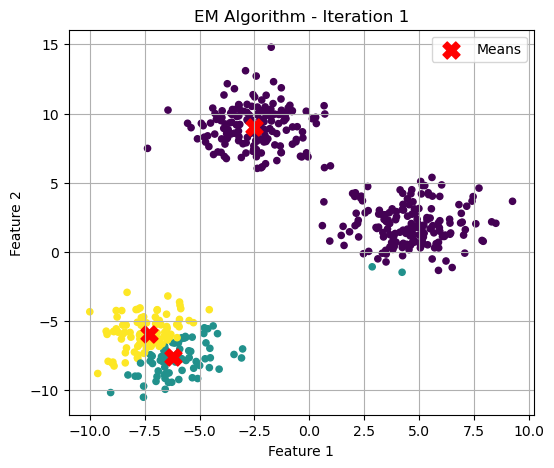

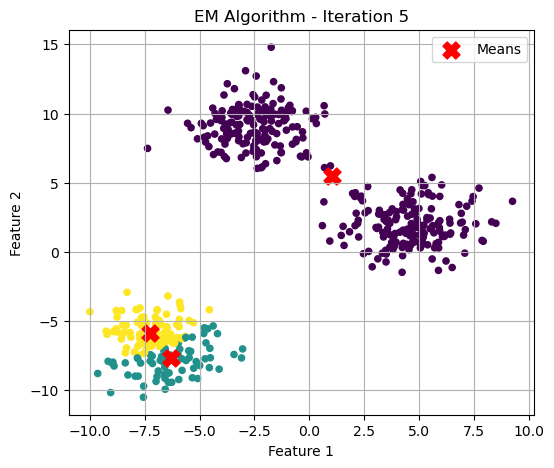

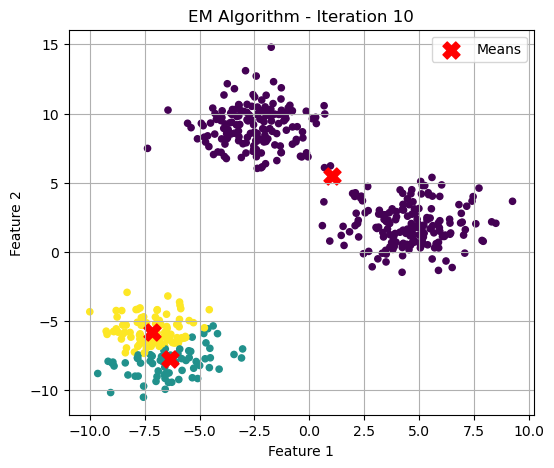

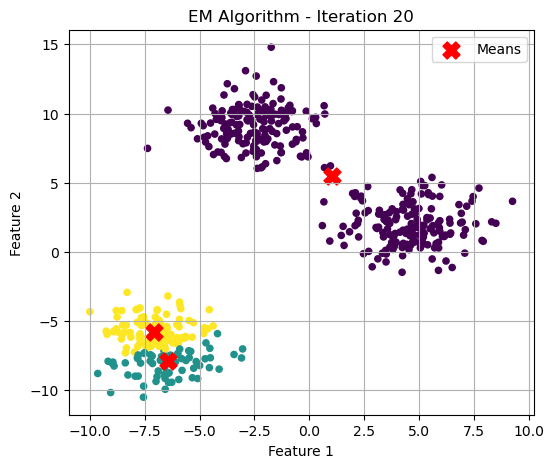

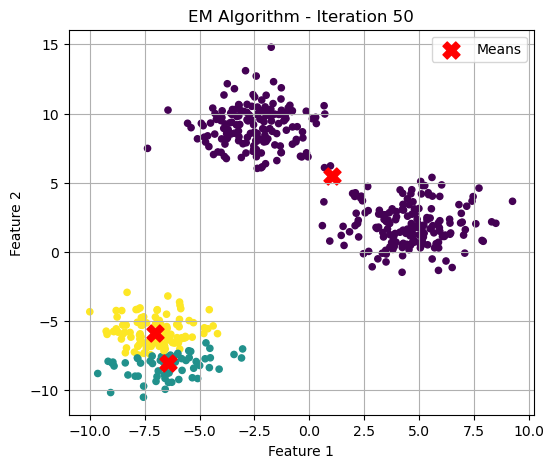

Final Means:
 [[ 1.04292437  5.47821287]
 [-6.44639759 -8.04883624]
 [-7.02483735 -5.87676805]]

Final Weights:
 [0.66799997 0.12503722 0.20696277]


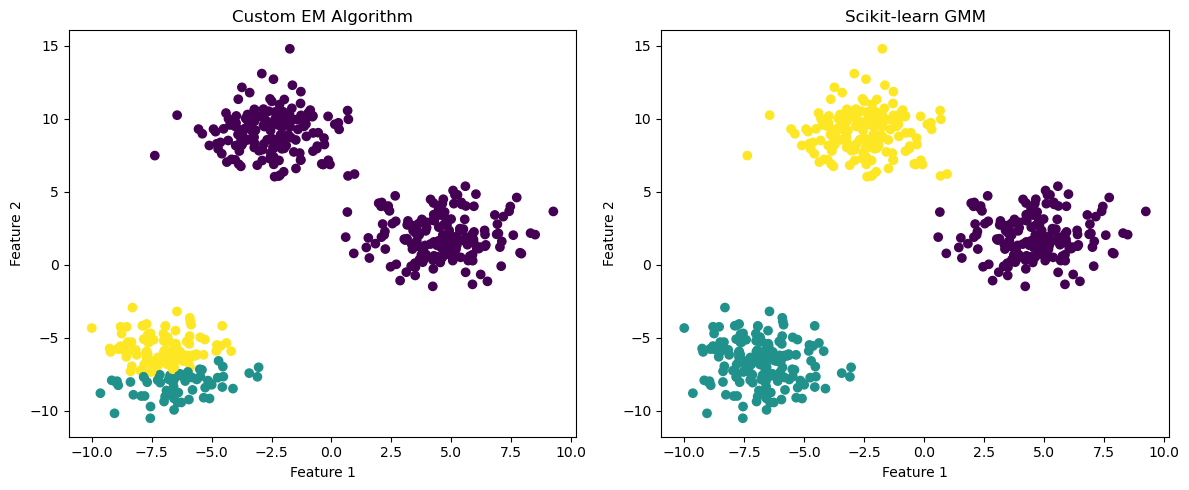


Custom EM Log Likelihood: -2535.732017873136
Sklearn GMM Log Likelihood: -2346.59424998148


In [2]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.mixture import GaussianMixture
from matplotlib.patches import Ellipse

# Step 1: Generate synthetic 2D dataset
X, y = make_blobs(
    n_samples=500,
    centers=3,
    n_features=2,
    cluster_std=1.5,
    random_state=42
)

# Step 2: Initialize GMM parameters
np.random.seed(42)

K = 3                       # Number of Gaussian components
n, d = X.shape

means = X[np.random.choice(n, K, replace=False)]
covariances = np.array([np.eye(d)] * K)
weights = np.ones(K) / K

# Gaussian probability density function
def gaussian(X, mean, cov):
    d = X.shape[1]
    diff = X - mean

    inv = np.linalg.inv(cov)
    det = np.linalg.det(cov)

    exponent = np.sum((diff @ inv) * diff, axis=1)
    denominator = np.sqrt((2 * np.pi) ** d * det)

    return np.exp(-0.5 * exponent) / denominator


# Step 3: EM Algorithm
for iteration in range(50):

    # E-step: Calculate responsibilities
    probabilities = np.zeros((n, K))

    for k in range(K):
        probabilities[:, k] = (
            weights[k] *
            gaussian(X, means[k], covariances[k])
        )

    responsibilities = probabilities / (
        probabilities.sum(axis=1, keepdims=True) + 1e-10
    )

    # M-step: Update parameters
    Nk = responsibilities.sum(axis=0)

    for k in range(K):
        means[k] = (
            responsibilities[:, k, None] * X
        ).sum(axis=0) / Nk[k]

        diff = X - means[k]

        covariances[k] = (
            (responsibilities[:, k, None] * diff).T @ diff
        ) / Nk[k]

        covariances[k] += np.eye(d) * 1e-6

        weights[k] = Nk[k] / n

    # Visualize selected iterations
    if iteration in [0, 4, 9, 19, 49]:
        labels = responsibilities.argmax(axis=1)

        plt.figure(figsize=(6, 5))
        plt.scatter(
            X[:, 0], X[:, 1],
            c=labels, cmap='viridis', s=20
        )

        plt.scatter(
            means[:, 0], means[:, 1],
            c='red', marker='X', s=150,
            label='Means'
        )

        plt.title(f'EM Algorithm - Iteration {iteration + 1}')
        plt.xlabel('Feature 1')
        plt.ylabel('Feature 2')
        plt.legend()
        plt.grid()
        plt.show()


# Step 4: Final clustering
labels = responsibilities.argmax(axis=1)

print("Final Means:\n", means)
print("\nFinal Weights:\n", weights)

# Step 5: Compare with Scikit-learn GMM
gmm = GaussianMixture(
    n_components=3,
    random_state=42
)

gmm.fit(X)
sklearn_labels = gmm.predict(X)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis')
plt.title("Custom EM Algorithm")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=sklearn_labels, cmap='viridis')
plt.title("Scikit-learn GMM")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.tight_layout()
plt.show()

print("\nCustom EM Log Likelihood:",
      np.sum(np.log(probabilities.sum(axis=1) + 1e-10)))

print("Sklearn GMM Log Likelihood:",
      gmm.score(X) * n)
